# Escudo Cidadão — Análise de URLs e identificação de phishing

**Global Solution FIAP 2026.2 | Inteligência Artificial e Machine Learning**

### 1. Introdução e pergunta de pesquisa

O phishing é um golpe digital em que uma página ou mensagem tenta induzir pessoas a fornecer senhas e dados pessoais. A ideia do **Escudo Cidadão** é investigar se as características **do texto de um link** ajudam a distinguir URLs legítimas de phishing.

**Pergunta:** qual é a diferença de desempenho entre um classificador treinado **com** e **sem** a informação de HTTPS?

**Hipótese:** o HTTPS é muito associado aos rótulos nesta base, mas isso não garante a segurança do link. Comparar os dois modelos ajuda a entender até que ponto o algoritmo depende dessa informação.

**Fonte:** [PhiUSIIL Phishing URL Dataset (UCI, 2024)](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), com 235.795 observações e 56 colunas originais. **Rótulo original:** `label=0` é phishing; `label=1` é legítima. O projeto converte para `phishing=1` (classe positiva) para facilitar a interpretação.

**Limites:** não fazemos acesso, download ou verificação ativa dos sites. Não usamos as colunas precomputadas do dataset, apenas os textos das URLs e os rótulos. Esta base **não atende ao recorte territorial de uma cidade** solicitado no edital; essa pendência está documentada, conforme a definição de escopo deste trabalho. Uma URL com HTTPS também pode ser phishing.

### 2. Bibliotecas utilizadas

Usamos `pandas` e `matplotlib` para explorar os dados, e `scikit-learn` para treinar e avaliar o Random Forest. `joblib` será utilizado somente para salvar os modelos e conectá-los à aplicação.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

### 3. Leitura da base original

O notebook lê o ZIP/CSV original na pasta `ml/dados/` (repositório) ou na pasta atual (Colab). Também permite fazer upload manual no Colab. **Nenhum link do dataset é aberto**.

In [2]:
arquivos = [
    "dados/phiusiil+phishing+url+dataset.zip",
    "phiusiil+phishing+url+dataset.zip",
    "../phiusiil+phishing+url+dataset.zip",
    "dados/PhiUSIIL_Phishing_URL_Dataset.csv",
    "PhiUSIIL_Phishing_URL_Dataset.csv",
]
arquivo = next((nome for nome in arquivos if Path(nome).exists()), None)

if arquivo is None:
    try:
        from google.colab import files
        arquivo = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("Coloque o ZIP ou CSV original na pasta dados/ ou ao lado do notebook.")

df = pd.read_csv(arquivo)
print("Registros e colunas originais:", df.shape)
display(df[["URL", "label"]].head())

Registros e colunas originais: (235795, 56)


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


### 4. Conhecendo e limpando os dados

Primeiro, verificamos a quantidade de valores ausentes e de URLs repetidas. Depois, mantemos apenas as colunas necessárias, removemos registros incompletos e criamos uma coluna `phishing`, em que **1 significa phishing** e **0 significa legítima**.

In [3]:
print("Valores ausentes nas colunas principais:")
print(df[["URL", "label"]].isna().sum())
print("URLs repetidas:", df.duplicated(subset="URL").sum())

Valores ausentes nas colunas principais:
URL      0
label    0
dtype: int64
URLs repetidas: 425


In [4]:
dados = df[["URL", "label"]].dropna().copy()
dados["URL"] = dados["URL"].str.strip()
dados = dados[dados["URL"] != ""]
dados = dados[dados["label"].isin([0, 1])]
dados = dados.drop_duplicates(subset="URL").copy()

dados["phishing"] = (dados["label"] == 0).astype(int)
dados["classe"] = dados["phishing"].map({0: "Legítima", 1: "Phishing"})

print("Registros antes da limpeza:", len(df))
print("Registros após a limpeza:", len(dados))

Registros antes da limpeza: 235795
Registros após a limpeza: 235370


### 5. Análise exploratória dos dados (EDA)

A análise exploratória nos ajuda a entender as classes e identificar diferenças entre os links antes de treinar o modelo.

classe
Legítima    134850
Phishing    100520
Name: count, dtype: int64


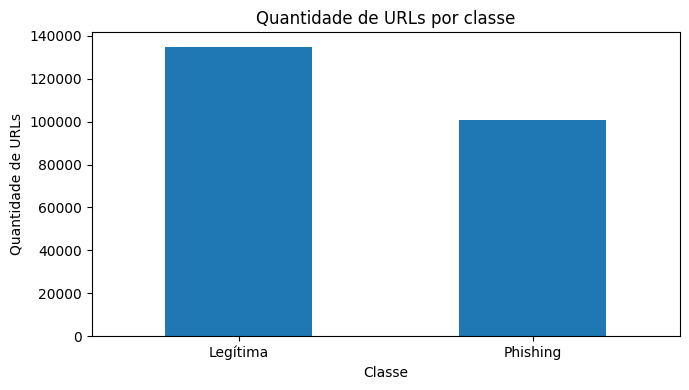

In [5]:
print(dados["classe"].value_counts())

dados["classe"].value_counts().reindex(["Legítima", "Phishing"]).plot(
    kind="bar", figsize=(7, 4), title="Quantidade de URLs por classe"
)
plt.xlabel("Classe")
plt.ylabel("Quantidade de URLs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 5.1. Comprimento das URLs

Criamos uma medida simples: o número de caracteres do link. Ela pode ser útil porque URLs muito compridas às vezes aparecem em golpes, embora isso não seja uma regra.

,mean,median,max
classe,,,
Legítima,27.2,27.0,58
Phishing,46.2,34.0,6097


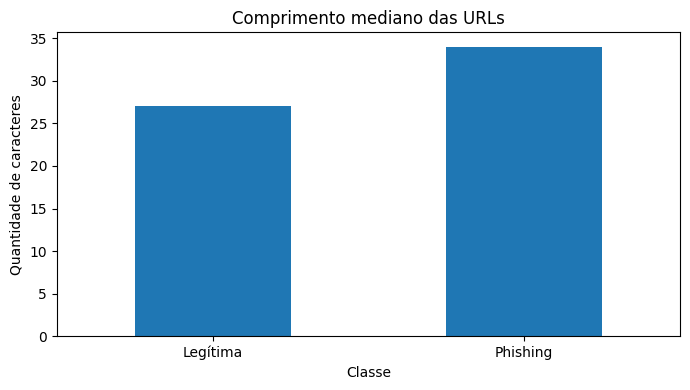

In [6]:
dados["tamanho_url"] = dados["URL"].str.len()

resumo = dados.groupby("classe")["tamanho_url"].agg(["mean", "median", "max"])
display(resumo.round(1))

dados.groupby("classe")["tamanho_url"].median().reindex(["Legítima", "Phishing"]).plot(
    kind="bar", figsize=(7, 4), title="Comprimento mediano das URLs"
)
plt.xlabel("Classe")
plt.ylabel("Quantidade de caracteres")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Engenharia de atributos (*feature engineering*)

Os algoritmos não entendem diretamente o texto da URL. Por isso, transformamos cada link em valores numéricos.

Foram criadas **8 variáveis simples**, relacionadas ao tamanho, à pontuação e a palavras presentes no endereço. Todas são calculadas a partir da própria URL, sem analisar o conteúdo da página.

In [7]:
url = dados["URL"]

dados["qtd_digitos"] = url.str.count(r"\d")
dados["qtd_pontos"] = url.str.count(r"\.")
dados["qtd_hifens"] = url.str.count("-")
dados["qtd_barras"] = url.str.count("/")
dados["qtd_especiais"] = url.str.count(r"[@?=&%]")
dados["usa_https"] = url.str.startswith("https://").astype(int)
dados["palavra_suspeita"] = url.str.contains(
    r"login|verify|account|secure|update|confirm", case=False, regex=True
).astype(int)

variaveis = [
    "tamanho_url", "qtd_digitos", "qtd_pontos", "qtd_hifens",
    "qtd_barras", "qtd_especiais", "usa_https", "palavra_suspeita"
]

display(dados[variaveis + ["phishing"]].head())

,tamanho_url,qtd_digitos,qtd_pontos,qtd_hifens,qtd_barras,qtd_especiais,usa_https,palavra_suspeita,phishing
0,32,0,2,0,2,0,1,0,0
1,24,0,2,1,2,0,1,0,0
2,30,0,3,0,2,0,1,0,0
3,27,0,2,0,2,0,1,0,0
4,34,0,2,0,2,0,1,0,0


#### 6.1. Relação entre HTTPS e as classes

Vamos observar a proporção de links com HTTPS em cada classe. **Importante:** HTTPS protege a conexão, mas não garante que o site seja confiável.

usa_https,Sem HTTPS (%),Com HTTPS (%)
classe,,
Legítima,0.0,100.0
Phishing,51.4,48.6


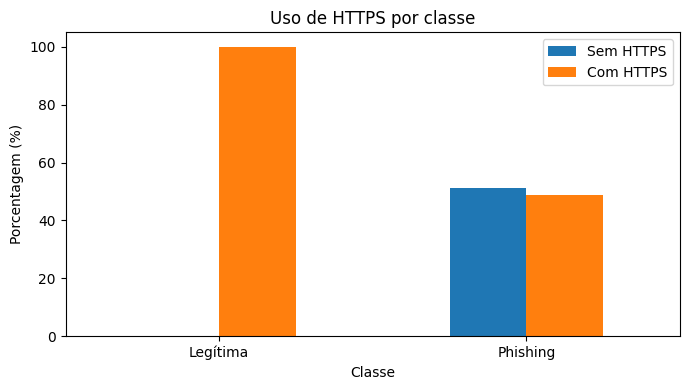

In [8]:
tabela_https = pd.crosstab(
    dados["classe"], dados["usa_https"], normalize="index"
) * 100

display(tabela_https.round(1).rename(columns={0: "Sem HTTPS (%)", 1: "Com HTTPS (%)"}))

tabela_https.plot(kind="bar", figsize=(7, 4), title="Uso de HTTPS por classe")
plt.ylabel("Porcentagem (%)")
plt.xlabel("Classe")
plt.xticks(rotation=0)
plt.legend(["Sem HTTPS", "Com HTTPS"])
plt.tight_layout()
plt.show()

### 7. Preparação para o Machine Learning

Separamos as **variáveis explicativas (X)** da **variável que queremos prever (y)**. Em seguida, usamos 80% dos registros para treinamento e 20% para teste, mantendo aproximadamente a proporção de cada classe.

In [9]:
X = dados[variaveis]
y = dados["phishing"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Linhas de treino:", len(X_treino))
print("Linhas de teste:", len(X_teste))

# A divisão é idêntica para os dois experimentos. O teste não participa da escolha de parâmetros.

Linhas de treino: 188296
Linhas de teste: 47074


### 8. Escolha do modelo e dos hiperparâmetros

Usaremos **Random Forest**, um conjunto de árvores de decisão que funciona bem com variáveis numéricas e dispensa normalização obrigatória neste caso.

O edital da GS exige **pelo menos 10 combinações envolvendo 3 hiperparâmetros**, com validação cruzada **somente nos dados de treino**. Escolhemos uma grade simples, de **12 combinações** (3 × 2 × 2):

- `n_estimators`: número de árvores (30, 50 ou 80);
- `max_depth`: profundidade máxima (8 ou 14);
- `min_samples_leaf`: mínimo de registros em cada folha (1 ou 4).

Aplicamos **3 divisões de validação cruzada estratificada**, usando a métrica **F1 de phishing**. Para acelerar a busca de parâmetros sem usar dados de teste, sorteamos **25 mil observações apenas do treino**, preservando a proporção entre as classes. Após a busca, cada modelo final é treinado **em todo o conjunto de treino**. Essa amostragem é uma escolha computacional declarada.

In [10]:
parametros = {
    "n_estimators": [30, 50, 80],
    "max_depth": [8, 14],
    "min_samples_leaf": [1, 4]
}

X_cv, _, y_cv, _ = train_test_split(
    X_treino, y_treino, train_size=25000, random_state=42, stratify=y_treino
)

validacao = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print("Combinações por experimento:", 3 * 2 * 2)
print("Linhas do treino usadas para buscar parâmetros:", len(X_cv))

Combinações por experimento: 12
Linhas do treino usadas para buscar parâmetros: 25000


### 9. Dois experimentos: com e sem HTTPS

Os dois modelos recebem **a mesma divisão de treino/teste** e a mesma estratégia de validação cruzada. A diferença é exclusivamente a presença da variável `usa_https`.

**Experimento A**: 8 variáveis, incluindo `usa_https`. **Experimento B**: 7 variáveis, sem `usa_https`.

In [11]:
variaveis_sem_https = [coluna for coluna in variaveis if coluna != "usa_https"]
experimentos = {
    "Com HTTPS": variaveis,
    "Sem HTTPS": variaveis_sem_https
}

modelos = {}
resultados_cv = []

for nome, colunas in experimentos.items():
    print("\nBuscando hiperparâmetros:", nome)
    busca = GridSearchCV(
        estimator=RandomForestClassifier(random_state=42, n_jobs=1),
        param_grid=parametros,
        scoring="f1",
        cv=validacao,
        n_jobs=2
    )
    busca.fit(X_cv[colunas], y_cv)
    modelos[nome] = busca.best_estimator_
    modelos[nome].set_params(n_jobs=2)
    modelos[nome].fit(X_treino[colunas], y_treino)

    resultados_cv.append({
        "Modelo": nome,
        "Melhor F1 na validação": busca.best_score_,
        "Melhores parâmetros": str(busca.best_params_),
        "Combinações avaliadas": len(busca.cv_results_["params"])
    })

display(pd.DataFrame(resultados_cv).round(4))


Buscando hiperparâmetros: Com HTTPS



Buscando hiperparâmetros: Sem HTTPS


,Modelo,Melhor F1 na validação,Melhores parâmetros,Combinações avaliadas
0,Com HTTPS,0.9935,"{'max_depth': 14, 'min_samples_leaf': 4, 'n_es...",12
1,Sem HTTPS,0.8087,"{'max_depth': 14, 'min_samples_leaf': 4, 'n_es...",12


### 10. Comparação de treino e teste

Para identificar possíveis sinais de **overfitting**, calculamos acurácia, precisão, recall e F1 em **treino e teste**. Um resultado muito melhor no treino do que no teste pode indicar que o modelo não generaliza tão bem.

In [12]:
linhas = []

for nome, colunas in experimentos.items():
    modelo = modelos[nome]
    for conjunto, X_parte, y_parte in [
        ("Treino", X_treino, y_treino),
        ("Teste", X_teste, y_teste)
    ]:
        previsto = modelo.predict(X_parte[colunas])
        linhas.append({
            "Modelo": nome,
            "Conjunto": conjunto,
            "Acurácia": accuracy_score(y_parte, previsto),
            "Precisão": precision_score(y_parte, previsto, zero_division=0),
            "Recall": recall_score(y_parte, previsto, zero_division=0),
            "F1": f1_score(y_parte, previsto, zero_division=0)
        })

resultados = pd.DataFrame(linhas)
display(resultados.round(4))

,Modelo,Conjunto,Acurácia,Precisão,Recall,F1
0,Com HTTPS,Treino,0.9958,0.9995,0.9908,0.9951
1,Com HTTPS,Teste,0.9959,0.9993,0.9910,0.9952
2,Sem HTTPS,Treino,0.8638,0.9750,0.6991,0.8143
3,Sem HTTPS,Teste,0.8627,0.9729,0.6979,0.8127


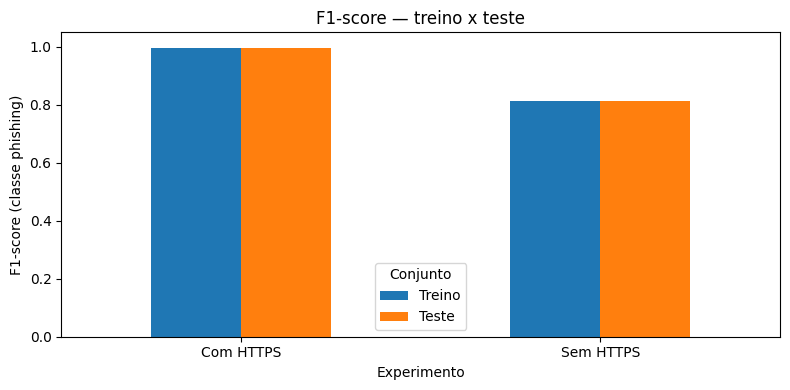

Diferença de F1 (treino menos teste):


Modelo
Com HTTPS   -0.0001
Sem HTTPS    0.0016
dtype: float64

In [13]:
grafico = resultados.pivot(index="Modelo", columns="Conjunto", values="F1")
grafico[["Treino", "Teste"]].plot(kind="bar", figsize=(8, 4))
plt.title("F1-score — treino x teste")
plt.ylim(0, 1.05)
plt.ylabel("F1-score (classe phishing)")
plt.xlabel("Experimento")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

diferenca = grafico["Treino"] - grafico["Teste"]
print("Diferença de F1 (treino menos teste):")
display(diferenca.round(4))

### 11. Matrizes de confusão e relatório de classificação

A matriz de confusão mostra **falsos negativos** (phishing previsto como legítimo) e **falsos positivos** (legítimo previsto como phishing). Para um problema de golpes, os falsos negativos merecem atenção especial.


 Com HTTPS
              precision    recall  f1-score   support

    Legítima       0.99      1.00      1.00     26970
    Phishing       1.00      0.99      1.00     20104

    accuracy                           1.00     47074
   macro avg       1.00      1.00      1.00     47074
weighted avg       1.00      1.00      1.00     47074



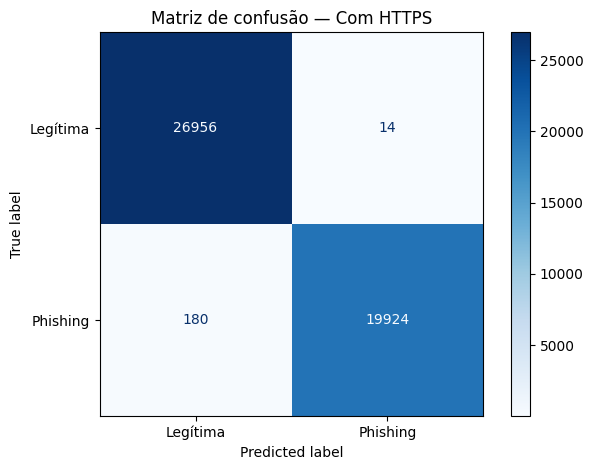


 Sem HTTPS
              precision    recall  f1-score   support

    Legítima       0.81      0.99      0.89     26970
    Phishing       0.97      0.70      0.81     20104

    accuracy                           0.86     47074
   macro avg       0.89      0.84      0.85     47074
weighted avg       0.88      0.86      0.86     47074



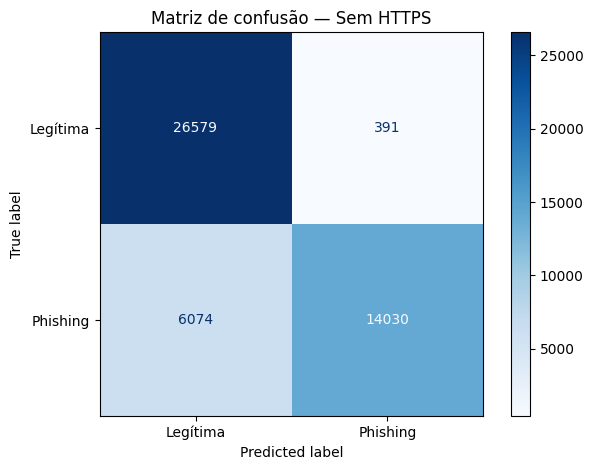

In [14]:
for nome, colunas in experimentos.items():
    previsto = modelos[nome].predict(X_teste[colunas])
    print("\n", nome)
    print(classification_report(y_teste, previsto, target_names=["Legítima", "Phishing"]))
    ConfusionMatrixDisplay.from_predictions(
        y_teste, previsto, display_labels=["Legítima", "Phishing"],
        cmap="Blues", values_format="d"
    )
    plt.title("Matriz de confusão — " + nome)
    plt.tight_layout()
    plt.show()

### 12. A importância do HTTPS e das demais variáveis

O valor `usa_https=1` significa que a URL **começa com** `https://`. O protocolo pode cifrar a conexão, mas **não assegura que o conteúdo do site seja confiável**. A importância da variável no modelo é uma associação estatística, não uma prova de causalidade.

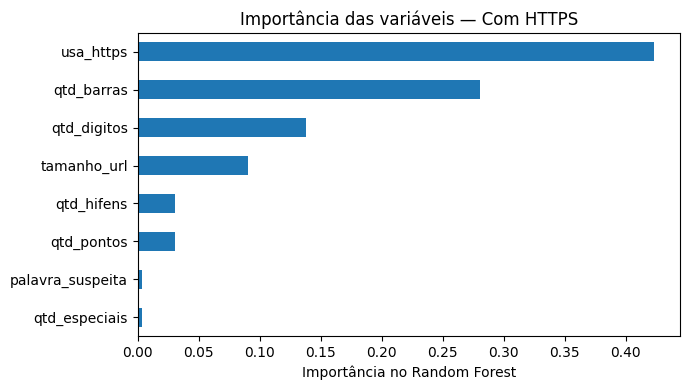

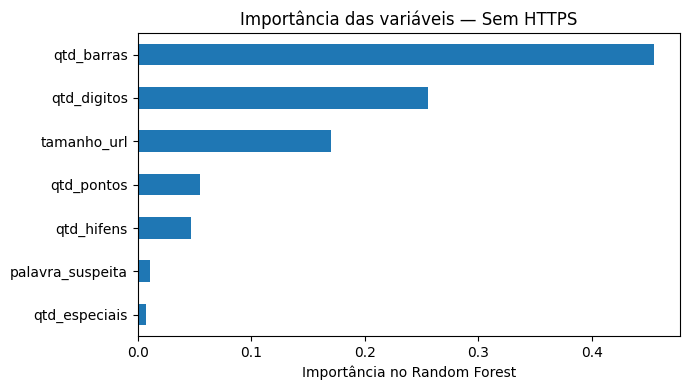

In [15]:
for nome, colunas in experimentos.items():
    importancias = pd.Series(modelos[nome].feature_importances_, index=colunas)
    importancias.sort_values().plot(kind="barh", figsize=(7, 4))
    plt.title("Importância das variáveis — " + nome)
    plt.xlabel("Importância no Random Forest")
    plt.tight_layout()
    plt.show()

### 13. Salvando os modelos para a aplicação prática

Cada arquivo `.joblib` guarda o classificador treinado e será utilizado pela plataforma simples em Streamlit. Em produção, modelos serializados devem ser carregados apenas de fontes confiáveis. A aplicação apenas analisa a string, **sem acessar nenhum site**.

In [16]:
pasta_modelos = Path("modelos")
pasta_modelos.mkdir(exist_ok=True)

joblib.dump(modelos["Com HTTPS"], pasta_modelos / "random_forest_com_https.joblib")
joblib.dump(modelos["Sem HTTPS"], pasta_modelos / "random_forest_sem_https.joblib")
resultados.to_csv(pasta_modelos / "resultados_treino_teste.csv", index=False)
pd.DataFrame(resultados_cv).to_csv(pasta_modelos / "resultados_validacao.csv", index=False)
print("Modelos e tabelas salvos em:", pasta_modelos.resolve())

Modelos e tabelas salvos em: /mnt/data/escudo_cidadao_gs/ml/modelos


### 14. Conclusão e significado para o cidadão

Concluímos um fluxo de Ciência de Dados com análise exploratória, limpeza, criação de 8 atributos, duas experiências com Random Forest, **12 combinações de três hiperparâmetros por experimento**, validação cruzada apenas no treino e análise das métricas de treino e teste.

**Resultado no teste:** com HTTPS, **99,59% de acurácia e 99,52% de F1**; sem HTTPS, **86,27% de acurácia e 81,27% de F1**. O recall para phishing caiu de **99,10%** para **69,79%** ao retirar HTTPS. Isso indica que o classificador se beneficia muito de um padrão específico desta amostra. No conjunto de teste, os falsos negativos aumentaram de **180 para 6.074**. As diferenças de F1 entre treino e teste foram pequenas nos dois modelos, mas isso não prova generalização para outros cenários.

**Interpretação:** HTTPS protege a conexão, mas **não garante** que o site seja confiável. A classificação fornecida pela futura plataforma é uma orientação educativa e não um certificado de segurança.

**Limitações:** (1) esta base não representa especificamente uma cidade brasileira; (2) possíveis vieses de origem e de rótulo; (3) não testamos generalização por domínio, tempo ou conjunto de dados externo; (4) analisamos só a string da URL, nunca o conteúdo da página.

**Fonte:** UCI Machine Learning Repository. *PhiUSIIL Phishing URL Dataset* (2024), dataset 967: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset.